In [1]:
import os
import numpy as np
import tensorflow as tf
os.environ["KERAS_BACKEND"] = "jax"
import keras
from keras import layers

In [2]:
filename = keras.utils.get_file(
    origin=(
        "https://storage.googleapis.com/download.tensorflow.org/"
        "data/shakespeare.txt"
    ),
)
shakespeare = open(filename, "r").read()

In [3]:
# Dividiamo il testo in segmenti di 100 caratteri.
# L’etichetta è lo stesso segmento spostato di una posizione

In [4]:
sequence_length = 100

def split_input(input, sequence_length):
    for i in range(0, len(input), sequence_length):
        yield input[i : i + sequence_length]

features = list(split_input(shakespeare[:-1], sequence_length))
labels = list(split_input(shakespeare[1:], sequence_length))
dataset = tf.data.Dataset.from_tensor_slices((features, labels))

In [5]:
for x, y in dataset.take(1):
    print(x)
    print(y)

tf.Tensor(b'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou', shape=(), dtype=string)
tf.Tensor(b'irst Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou ', shape=(), dtype=string)


In [6]:
# Prendiamo ogni carattere e lo trasformiamo in una sequenza di 100 numeri

tokenizer = layers.TextVectorization(
    standardize=None,
    split="character",
    output_sequence_length=sequence_length,
)
tokenizer.adapt(dataset.map(lambda text, labels: text))

In [7]:
vocabulary_size = tokenizer.vocabulary_size()
vocabulary_size

67

In [8]:
dataset = dataset.map(
    lambda features, labels: (tokenizer(features), tokenizer(labels)),
    num_parallel_calls=tf.data.AUTOTUNE,
)
training_data = dataset.shuffle(10_000).batch(64).cache()

In [ ]:
# Quanto è lunga la sequenza di token? Posso avere massimo 100 numeri

inputs = keras.Input(
    shape=(100,)
)

# input_dim = quanti ID diversi può gestire l'embedding
# in altre parole, dato che un ID è un carattere, stiamo dicendo alla rete
# quanti caratteri deve inserire in ogni seguenza analizzata dalla LSTM

# output_dim = la dimensione che ogni elemento della sequenza di input avrà
# in altre parole, l'output avrà dimensione 100 x 64 (100 righe x 64 colonne)

x = layers.Embedding(
    input_dim=100,
    output_dim=64,
    mask_zero=True,
    name="work_embedding"
)(inputs)
x = layers.LSTM(256, return_sequences=True)(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(100, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)

In [10]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ work_embedding      │ (None, 100, 64)   │      6,400 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 100)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 100, 256)  │    328,704 │ work_embedding[0… │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 100, 256)  │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 100, 100)  │     25,700 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 360,804 (1.38 MB)

 Trainable params: 360,804 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
dataset = dataset.batch(64).cache()
# dataset= dataset.unbatch()


In [12]:
history = model.fit(training_data, epochs=20)

Epoch 1/20


/opt/miniconda3/envs/ai_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


175/175 ━━━━━━━━━━━━━━━━━━━━ 21s 118ms/step - loss: 2.9133 - sparse_categorical_accuracy: 0.2337
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 21s 120ms/step - loss: 2.2920 - sparse_categorical_accuracy: 0.3421
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 22s 123ms/step - loss: 2.1150 - sparse_categorical_accuracy: 0.3858
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 22s 127ms/step - loss: 1.9967 - sparse_categorical_accuracy: 0.4144
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 24s 138ms/step - loss: 1.9081 - sparse_categorical_accuracy: 0.4375
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 24s 139ms/step - loss: 1.8401 - sparse_categorical_accuracy: 0.4572
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 141ms/step - loss: 1.7867 - sparse_categorical_accuracy: 0.4720
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 147ms/step - loss: 1.7427 - sparse_categorical_accuracy: 0.4833
Epoch 9/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 151ms/step - loss: 1.7071 - sparse_categorical_accuracy: 0.4934
Epoch 10/20
175/175 ━━━━━━━━━━━━━━━━━━━

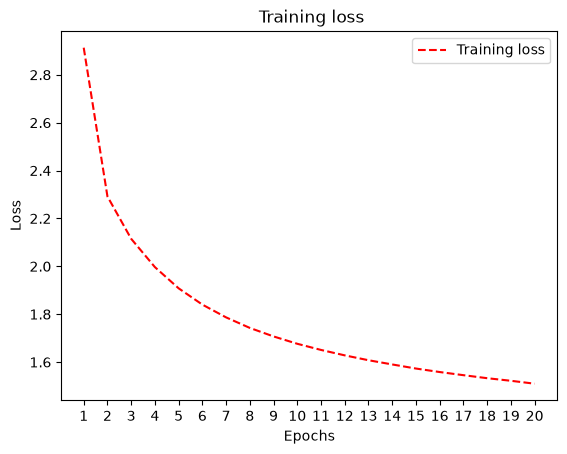

In [13]:
import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
# val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "r--", label="Training loss")
# plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title(" Training loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

In [14]:
def genera_testo(testo_iniziale, nuovi_caratteri=200):
    testo = testo_iniziale
    vocabulary = tokenizer.get_vocabulary()

    for _ in range(nuovi_caratteri):
        # Usa al massimo gli ultimi 100 caratteri.
        contesto = testo[-sequence_length:]

        # Il tokenizer aggiunge padding fino a 100 token.
        token_ids = tokenizer(tf.constant([contesto]))

        # Forma: (1, 100, vocabulary_size)
        predictions = model.predict(token_ids, verbose=0)

        # Prendi la previsione dopo l'ultimo carattere reale.
        posizione = len(contesto) - 1
        probabilities = predictions[0, posizione].copy()

        # Escludi padding e token sconosciuto.
        probabilities[:2] = 0
        probabilities /= probabilities.sum()

        # Estrai un carattere secondo le probabilità previste.
        next_id = np.random.choice(
            len(probabilities),
            p=probabilities,
        )

        testo += vocabulary[next_id]

    return testo


print(genera_testo("Before", nuovi_caratteri=300))

Before, at you. Go, marraw they valse's sleamony'd
As allain for all countions; fear all bind:
The night his sing with thiss down your belpialded
Kas! do thou knows we meant, or thine is a stare,
And but,
Whither's our sorrow, do now will fair all my compiniss'd here,
Neigh'd that thy rest: conscient whro
